<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/prediction/index.html">Weather, Climate and Prediction</a><span class="sep">·</span>Part 8 · Detecting climate change</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Assumes <a href="/blogs/trend-significance/is_the_trend_significant.html">Is the trend significant?</a>.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Warming becomes obvious at a place when it is large compared with how much that place's years normally vary. That ratio, signal to noise, matters more than the warming itself. Tropical places warm less than mid-latitudes, but their years scatter far less, so their expected temperature reaches two standard deviations above the old mean, the usual "time of emergence", decades sooner. Even then about half of years stay below that line, and 2.3% fall below the old average. In two synthetic stations, one warming 0.15 °C per decade with year-to-year noise of 0.25 °C emerges 33 years after the middle of its 1951–1980 baseline; one warming 0.25 °C per decade with noise of 0.80 °C takes 64 years. In 2020 the noisier station still has a 4.4% chance each year of falling below its old average. A cold year at one station is expected, not a contradiction. Averaging stations or years raises the ratio, but shared weather and year-to-year memory limit the gain.

Compare places by noise divided by warming rate, and average before looking for a trend.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
c1, c2, c3, c4 = fallcolor.palette.discrete("default")
rng = np.random.default_rng(2026)

[Is the trend significant?](../trend-significance/is_the_trend_significant.ipynb) asked whether a fitted slope is distinguishable from zero. This module asks a question closer to experience: when does a typical year at one place lie outside the range of years it used to have? The answer depends less on how fast a place warms than on how much its years scatter.

## Signal, noise and time of emergence

The signal-to-noise ratio says how many "normal years' worth" of spread the warming has added. Hawkins and Sutton define the signal $S$ as the forced change in temperature relative to a reference period, the noise $N$ as the standard deviation of seasonal or annual means from one year to the next, and the **time of emergence** (ToE) as the first year in which $S/N$ crosses a chosen threshold, such as 1 or 2[^1]. For a straight-line warming:

$$
\frac{S}{N}(t) = \frac{\omega\,(t - t_0)}{\sigma}, \qquad \text{ToE} = t_0 + \frac{k\,\sigma}{\omega},
$$

where $t$ is the year, $t_0$ the middle of the baseline period (the reference years whose average defines "normal", as in [What a climatology is](../what-a-climatology-is.qmd)), $\omega$ the warming rate (°C per year), $\sigma$ the year-to-year standard deviation of annual [anomalies](../anomalies/anomalies.ipynb) about the trend (°C), and $k$ the threshold (no units). With $k = 2$, emergence is the year when the *expected* anomaly reaches $2\sigma$ above the old mean. Single years still scatter around that expectation: at emergence about half of them lie above the old $+2\sigma$ edge and half below it, and 2.3% still fall below the old average. That last figure is $\Phi(-S/N)$ at $S/N = 2$, the cold-year probability used later in this module.

The ratio $\sigma/\omega$ is the number of years of warming it takes to equal one standard deviation of noise. Doubling the noise delays emergence exactly as much as halving the warming. Copy this helper:

In [2]:
def time_of_emergence(trend, noise_sd, k=2):
    # Years after the baseline midpoint when a linear trend (°C/yr) reaches k noise standard deviations (°C).
    return k * noise_sd / trend


# At emergence (S/N = k = 2), with normal noise around the expected anomaly:
print(f"years below the old average {100 * stats.norm.cdf(-2):.1f}%, above the old +2 sigma edge {100 * stats.norm.sf(0):.0f}%")

years below the old average 2.3%, above the old +2 sigma edge 50%


::: {.callout-note collapse="true"}
## Choices hidden in the definition

Two choices move the answer, and each study states its own. (Hawkins and Sutton's signal is also not a straight line: they scale local change to smoothed global warming, relative to 1986–2005[^1].)

- **Threshold $k$.** Hawkins and Sutton map both $S/N > 1$ and $S/N > 2$[^1]. Mahlstein and colleagues instead test whether the distribution of summer temperatures in a later period differs from that of a base period, 1900–1929, at the 95% level; one of their three tests flags a change when the difference in means exceeds twice the interannual variability, and they report that the choice of test does not materially change the results[^2].
- **Noise.** Hawkins and Sutton take the interannual standard deviation from each model's control run, without human influence; they note that earlier studies used the variability of 20-year averages, which is smaller and so gives earlier emergence[^1]. In observations the noise must be estimated from a record that already contains a trend, so it has to be detrended first.
:::

## Why the tropics emerge first

Low-latitude places see a smaller warming but emerge earlier, because their years scatter so little. Mahlstein and colleagues, using 23 climate models and the GISTEMP observations, find that the largest warming is expected at high latitudes but the largest variability is there too, and that the earliest significant warming appears in summer in low-latitude countries, roughly 25° S to 25° N[^2]. Hawkins and Sutton find interannual variability generally greater at higher latitudes and over land, with the El Niño region and the Barents Sea as exceptions. Their median model time of emergence for $S/N > 2$ falls before 2030 for many tropical regions and after 2060 for many extratropical ones, with a spread between models of at least 30 years[^1]. The two papers measure noise on different averages: Mahlstein and colleagues use summer means (the three warmest months), Hawkins and Sutton annual and half-year means.

Why the tropics are so steady is background rather than a finding of these two papers, and the summary is mine. Near the equator horizontal temperature gradients are weak and passing weather systems (fronts, cyclones and anticyclones) are few, so little drives a whole season far from its usual value; the El Niño region of the Pacific is the exception. At higher latitudes and in continental interiors, storm tracks shift from year to year and snow and sea-ice cover amplify warm and cold anomalies, so seasons swing more.

The two stations below are synthetic and describe no real place. Each has annual anomalies relative to a 1951–1980 baseline (so $t_0 = 1965.5$), a straight-line warming, and normal noise with a fixed $\sigma$ that is independent from year to year (white). Neither paper quotes regional values of $\sigma$ in its text (both show maps), so these values are illustrative, not measured; they follow the sources' ordering only:

| synthetic station | warming $\omega$ | noise $\sigma$ |
|---|---|---|
| "tropical" | 0.15 °C per decade | 0.25 °C |
| "mid-latitude" | 0.25 °C per decade | 0.80 °C |

In [3]:
years = np.arange(1951, 2051)
t0 = 1965.5                                    # middle of the 1951-1980 baseline
stations = {"tropical": (0.015, 0.25), "mid-latitude": (0.025, 0.80)}   # (trend °C/yr, noise SD °C), synthetic
series = {name: w * (years - t0) + rng.normal(0, sd, len(years)) for name, (w, sd) in stations.items()}

for name, (w, sd) in stations.items():
    base = series[name][years <= 1980]
    sd_hat = np.std(base - np.polyval(np.polyfit(years[years <= 1980], base, 1), years[years <= 1980]), ddof=2)
    print(f"{name:12s} true ToE {t0 + time_of_emergence(w, sd):.0f}; "
          f"noise SD estimated from the 30 baseline years {sd_hat:.2f} °C (true {sd}) "
          f"-> ToE {t0 + time_of_emergence(w, sd_hat):.0f}")

tropical     true ToE 1999; noise SD estimated from the 30 baseline years 0.20 °C (true 0.25) -> ToE 1993
mid-latitude true ToE 2030; noise SD estimated from the 30 baseline years 0.80 °C (true 0.8) -> ToE 2030


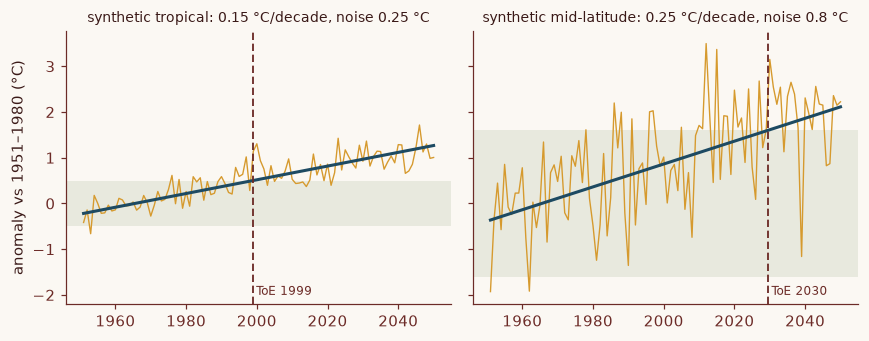

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
for ax, (name, (w, sd)) in zip(axes, stations.items()):
    toe = t0 + time_of_emergence(w, sd)
    ax.axhspan(-2 * sd, 2 * sd, color=c4, alpha=0.18, lw=0)
    ax.plot(years, series[name], color=c2, lw=0.9)
    ax.plot(years, w * (years - t0), color=c1, lw=2)
    ax.axvline(toe, color=c3, lw=1.2, ls=(0, (4, 2)))
    ax.text(toe + 1, -2.0, f"ToE {toe:.0f}", fontsize=8, color=c3)
    ax.set_title(f"synthetic {name}: {10 * w:.2f} °C/decade, noise {sd} °C", fontsize=9)
axes[0].set_ylabel("anomaly vs 1951–1980 (°C)")
fig.tight_layout()
plt.show()

<strong>Figure 1 | Smaller warming, earlier emergence.</strong> Synthetic annual anomalies (thin), the built-in warming (thick), and the band of ±2 standard deviations of year-to-year noise around the old normal (shaded). The dashed line is the time of emergence for $k = 2$, when the expected anomaly reaches the top of the band.

The tropical station warms more slowly yet emerges in 1999, about three decades before the mid-latitude station's 2030: $2 \times 0.25 / 0.015 = 33$ years after 1965.5, against $2 \times 0.80 / 0.025 = 64$. The rest of each printed line is a warning. In practice the noise must itself be estimated, and 30 baseline years pin a standard deviation down only to within roughly 13% ($1/\sqrt{2 \times 29}$, the large-sample relative standard error of a standard deviation). The cell estimates it the way you would on a real record: fit a line to the baseline years and take the standard deviation of the residuals (after first converting to [anomalies](../anomalies/anomalies.ipynb) if the data are daily or monthly). In this draw the tropical estimate came out at 0.20 °C instead of 0.25 °C, which moves its emergence from 1999 to 1993.

## A cold year at one station

A cold year at one station is expected, not a contradiction, for decades after the warming has begun. If anomalies scatter normally around the trend line, the chance that a given year falls below the old baseline average is

$$
P(\text{below old normal}) = \Phi\!\left(-\frac{S}{N}\right),
$$

where $\Phi$ is the standard normal cumulative distribution function. The cell below evaluates it for both stations, and counts the cold years in the synthetic records after 2000.

In [5]:
rows = {}
for name, (w, sd) in stations.items():
    rows[name] = {f"{yr}": 100 * stats.norm.cdf(-w * (yr - t0) / sd) for yr in (1980, 2000, 2020, 2040)}
print(pd.DataFrame(rows).T.round(1).to_string())    # % chance a year is below the 1951-1980 average

for name, (w, sd) in stations.items():
    later = series[name][years > 2000]
    print(f"{name:12s} 2001-2050: {np.sum(later < 0)} of {len(later)} years below the old normal; "
          f"{np.sum(np.diff(series[name]) < 0)} of {len(years) - 1} years colder than the year before")
print(f"chance any year is colder than the one before, mid-latitude: {100 * stats.norm.cdf(-0.025 / (0.8 * np.sqrt(2))):.1f}%")

              1980  2000  2020  2040
tropical      19.2   1.9   0.1   0.0
mid-latitude  32.5  14.0   4.4   1.0
tropical     2001-2050: 0 of 50 years below the old normal; 45 of 99 years colder than the year before
mid-latitude 2001-2050: 3 of 50 years below the old normal; 50 of 99 years colder than the year before
chance any year is colder than the one before, mid-latitude: 49.1%


In 2020, 54.5 years after the baseline midpoint, the synthetic mid-latitude station still has a 4.4% chance each year of falling below its 1951–1980 average, against 0.1% for the tropical one; in 2000 the figures were 14.0% and 1.9%. The simulated records agree: after 2000, 3 of the mid-latitude station's 50 years fall below the old normal and none of the tropical station's. And the year-on-year comparison, the one people make, is close to a coin toss: at the mid-latitude station 49.1% of years are expected to be colder than the year before (50 of 99 in the simulated record), because one year's warming (0.025 °C) is tiny next to the difference of two noisy years (standard deviation $0.80\sqrt{2} = 1.13$ °C).

By the same 14.0%, a large network of such stations would report about one in seven below-normal in 2000, every one of them warming (fewer or more in a given year, since real neighbours share weather). A single station's cold year is one draw from a distribution whose centre has moved; it says little about the centre, which is what the trend measures.

## Averaging over space and time

Averaging cancels part of the noise and none of the shared signal, so it raises the ratio and brings emergence forward. For the mean of $n$ stations that share the same trend and whose noise has standard deviation $\sigma$ and pairwise correlation $\rho$:

$$
\sigma_{\bar n} = \sigma \sqrt{\rho + \frac{1 - \rho}{n}},
$$

where $\sigma_{\bar n}$ (°C) is the noise standard deviation of the average and $\rho$ (no units) the correlation between two stations' anomalies. With independent noise ($\rho = 0$) the noise falls as $1/\sqrt{n}$. With shared weather it cannot fall below $\sigma\sqrt{\rho}$: neighbouring stations have their warm and cold years together (the reason records are averaged as [anomalies](../anomalies/anomalies.ipynb) at all), and averaging them does not cancel what they share. Hawkins and Sutton make the same point for regions: because noise variance falls with averaging, the ToE of an area mean is generally earlier than the average ToE of the places in it[^1].
(The formula is the average of all $n^2$ variances and covariances of the stations; the cell below checks it by simulation.)

In [6]:
def noise_of_mean(sd, n, rho):
    return sd * np.sqrt(rho + (1 - rho) / n)


n, rho, sd = 16, 0.5, 0.80                     # synthetic network: 16 stations, correlation 0.5
cov = sd**2 * (rho * np.ones((n, n)) + (1 - rho) * np.eye(n))
sims = rng.multivariate_normal(np.zeros(n), cov, size=20000).mean(axis=1)
print(f"16 stations, rho = 0.5: simulated noise SD {sims.std():.3f} °C, formula {noise_of_mean(sd, n, rho):.3f} °C")

w = 0.025                                      # mid-latitude trend, °C/yr
for rho in (0, 0.5, 0.8):
    toes = [time_of_emergence(w, noise_of_mean(sd, k, rho)) for k in (1, 4, 16, 64)]
    print(f"rho = {rho}: ToE for 1, 4, 16, 64 stations = " + ", ".join(f"{x:.0f}" for x in toes) + " years")


def n_eff_mean(m, phi):
    # Effective number of independent years in an m-year mean of AR(1) noise (exact variance of the mean).
    k = np.arange(1, m)
    return m / (1 + 2 * np.sum((1 - k / m) * phi**k))


for phi in (0, 0.3, 0.5):                      # phi: lag-1 correlation of annual anomalies
    ne = n_eff_mean(10, phi)
    print(f"one station, 10-year means, phi = {phi}: n_eff = {ne:.1f} of 10 years, "
          f"ToE {time_of_emergence(w, sd / np.sqrt(ne)):.0f} years (at the window's centre)")

16 stations, rho = 0.5: simulated noise SD 0.584 °C, formula 0.583 °C
rho = 0: ToE for 1, 4, 16, 64 stations = 64, 32, 16, 8 years
rho = 0.5: ToE for 1, 4, 16, 64 stations = 64, 51, 47, 46 years
rho = 0.8: ToE for 1, 4, 16, 64 stations = 64, 59, 58, 57 years
one station, 10-year means, phi = 0: n_eff = 10.0 of 10 years, ToE 20 years (at the window's centre)
one station, 10-year means, phi = 0.3: n_eff = 5.8 of 10 years, ToE 27 years (at the window's centre)
one station, 10-year means, phi = 0.5: n_eff = 3.8 of 10 years, ToE 33 years (at the window's centre)


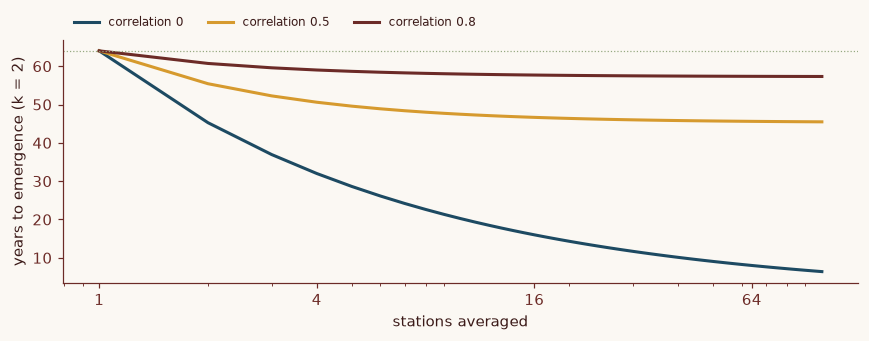

In [7]:
ns = np.arange(1, 101)
fig, ax = plt.subplots(figsize=(8, 3.2))
for rho, col in zip((0, 0.5, 0.8), (c1, c2, c3)):
    ax.plot(ns, time_of_emergence(w, noise_of_mean(sd, ns, rho)), color=col, lw=2, label=f"correlation {rho}")
ax.axhline(time_of_emergence(w, sd), color=c4, lw=0.8, ls=":")
ax.set_xscale("log")
ax.set_xticks([1, 4, 16, 64], ["1", "4", "16", "64"])
ax.set(xlabel="stations averaged", ylabel="years to emergence (k = 2)")
ax.legend(fontsize=8, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout()
plt.show()

<strong>Figure 2 | Averaging brings emergence forward until shared weather sets a floor.</strong> Time of emergence for the mean of $n$ synthetic mid-latitude stations (0.25 °C per decade, noise 0.80 °C each), for three values of the correlation between stations' noise. The dotted line is a single station.

The formula holds: 0.584 °C from 20 000 simulated years against 0.583 °C. For the synthetic mid-latitude station, emergence 64 years after the baseline midpoint comes down to 16 years for 16 independent stations, and to 47 years when the stations' noise is correlated at 0.5; with correlation 0.8, even 64 stations need 57 years. Averaging in time works the same way: 10-year means of independent years emerge after 20 years instead of 64, which is why studies using 20-year means, as Hawkins and Sutton note, find earlier emergence than those using single years[^1]. That is the best case. Real annual temperatures carry some memory from one year to the next, and with a lag-1 correlation $\phi$ a 10-year mean holds fewer than 10 independent years. The cell uses the exact variance of an AR(1) mean, the finite-length version of the $n(1-\phi)/(1+\phi)$ rule in [Is the trend significant?](../trend-significance/is_the_trend_significant.ipynb). At $\phi = 0.3$ it counts as 5.8 years and emergence moves to 27 years; at $\phi = 0.5$, 3.8 years and 33 years, so 13 of the 44 years gained are lost. The values of $\phi$ are illustrative. A regional or global average shows the warming long before a single station does for the same reason: it averages places whose year-to-year weather is only partly shared. The ratio has improved; the warming has not changed.

Whether the signal that emerges is caused by human activity is a further question, taken up in [Attribution](../attribution.qmd).

::: {.callout-tip}
## What this means for you

My inference from the arithmetic above and the two sources:

- Before comparing how fast two places "feel" climate change, compare $\sigma/\omega$, not $\omega$ alone.
- To see a trend in your own site's records, average first: several nearby stations, a season, or several years, and state which.
- Read a cold year at one site as one draw from a shifted distribution. Ask what fraction of years fall below the old normal, and compare that with $\Phi(-S/N)$.
:::

## Key takeaways

- Quote a time of emergence with its threshold $k$, its baseline and how the noise was measured; each changes the year.
- Estimate the noise from detrended data, and carry its sampling error into the emergence year.
- Expect about half of all years to be colder than the year before, even in a steadily warming record.
- Averaging stations helps only as far as their noise is independent; check the correlation before counting stations.
- Before averaging years, measure their lag-1 correlation; memory shrinks the effective number of years.

## References

[^1]: Hawkins, E. & Sutton, R. Time of emergence of climate signals. *Geophys. Res. Lett.* **39**, L01702 (2012). https://doi.org/10.1029/2011GL050087
[^2]: Mahlstein, I., Knutti, R., Solomon, S. & Portmann, R. W. Early onset of significant local warming in low latitude countries. *Environ. Res. Lett.* **6**, 034009 (2011). https://doi.org/10.1088/1748-9326/6/3/034009

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/heatwaves-in-a-warming-climate.html"><span>Previous</span>Heatwaves in a warming climate</a><a class="mf-up" href="/series/prediction/index.html"><span>Series</span>Weather, Climate and Prediction</a><a class="mf-next" href="/blogs/attribution.html"><span>Next</span>Attribution</a></div>
<!-- CURRICULUM_FOOTER_END -->